## Import

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load

In [2]:
df = pd.read_csv("Unemployment in India.csv")

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## Clean column names

In [3]:
df.columns = df.columns.str.strip()

df.columns

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')

## Basic inspection

In [4]:
print("Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (768, 7)

Data Types:
Region                                      object
Date                                        object
Frequency                                   object
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                        object
dtype: object

Missing Values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


## Convert Date

In [5]:
df["Date"] = pd.to_datetime(
    df["Date"],
    dayfirst=True,
    errors="coerce"
)

In [6]:
df["Date"].head()

0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[ns]

## Remove missing rows

In [7]:
df = df.dropna()

## Region-wise unemployment

In [8]:
region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

region_avg.head(10)

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64

## Plot region-wise average

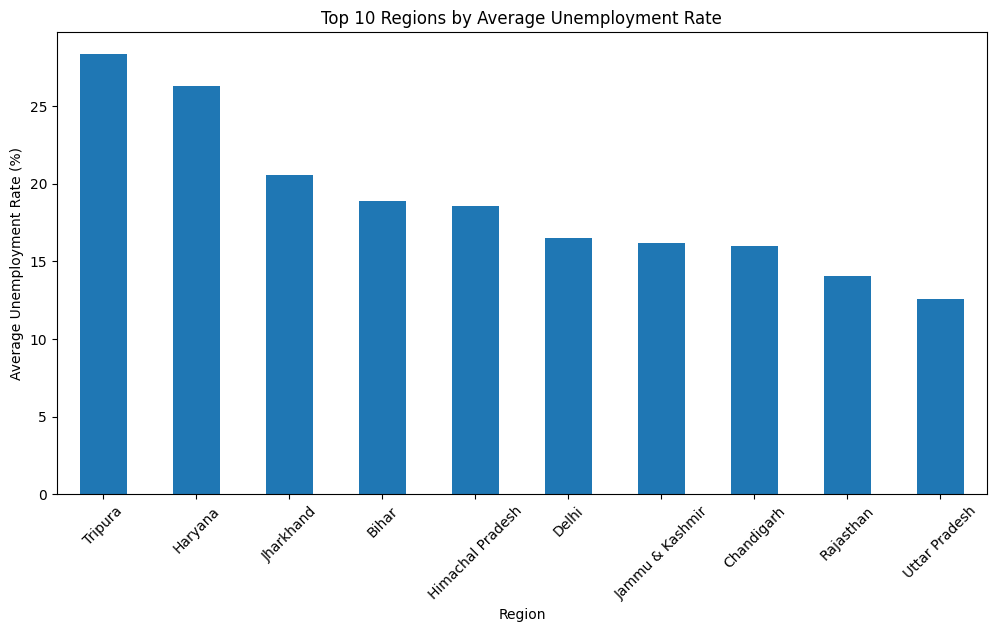

In [9]:
plt.figure(figsize=(12, 6))

region_avg.head(10).plot(kind="bar")

plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)

plt.show()

## Month-wise trend

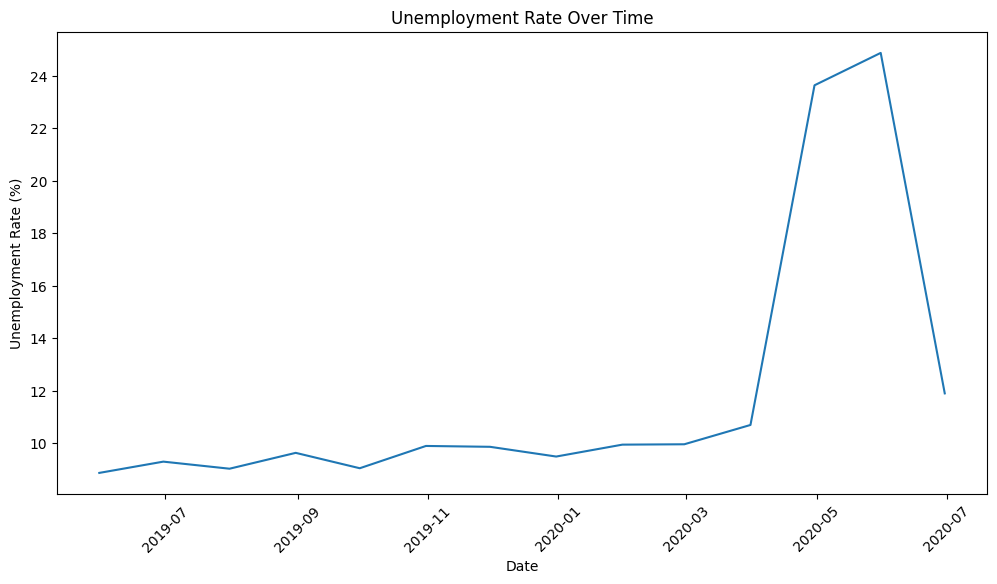

In [10]:
monthly = (
    df.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly.index,
    monthly.values
)

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)

plt.show()

## Choose 3 regions

In [11]:
df["Region"].unique()

array(['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa',
       'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh',
       'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab',
       'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura',
       'Uttar Pradesh', 'Uttarakhand', 'West Bengal', 'Chandigarh'],
      dtype=object)

In [14]:
selected_regions = [
    "Andhra Pradesh",
    "Bihar",
    "Delhi"
]

## Plot 3 regions

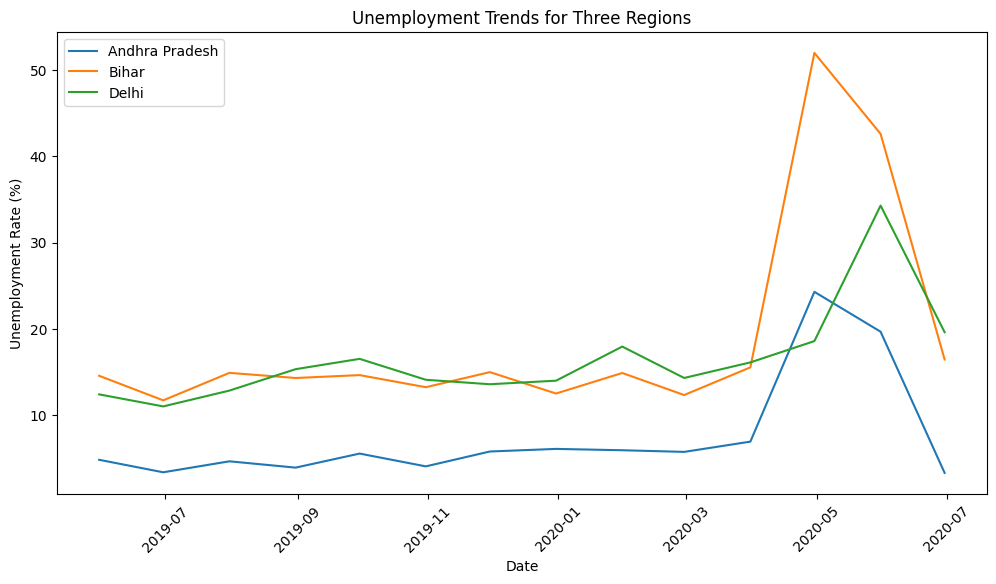

In [15]:
plt.figure(figsize=(12, 6))

for region in selected_regions:

    temp = df[df["Region"] == region]

    temp = temp.groupby("Date")[
        "Estimated Unemployment Rate (%)"
    ].mean()

    plt.plot(
        temp.index,
        temp.values,
        label=region
    )

plt.title("Unemployment Trends for Three Regions")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.legend()
plt.xticks(rotation=45)

plt.show()

## Correlation heatmap

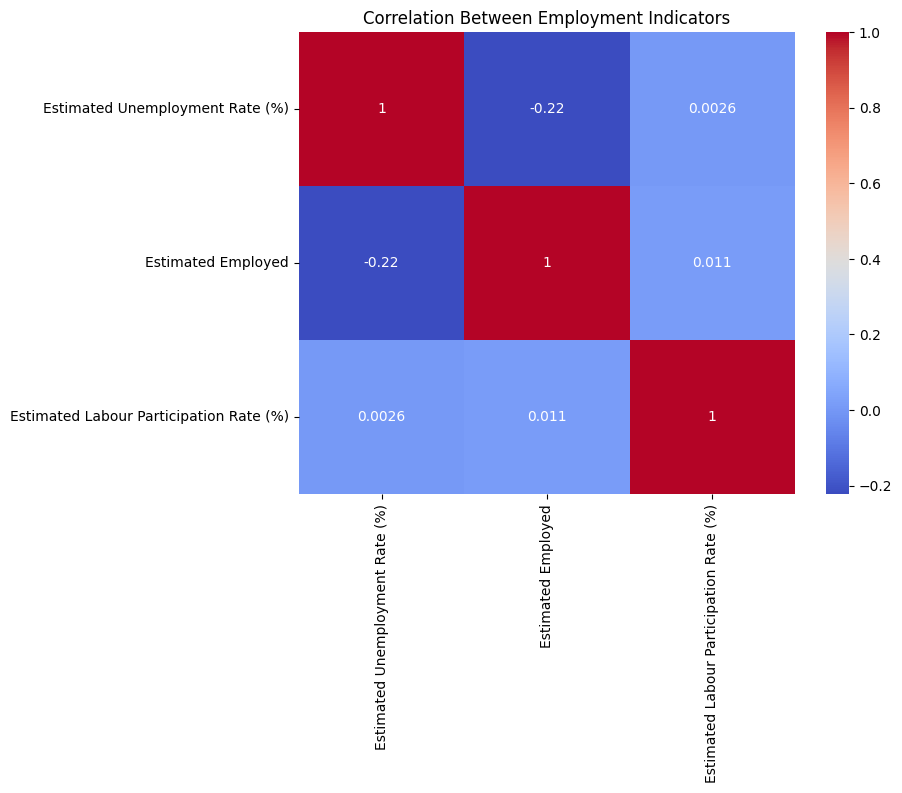

In [16]:
numeric_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Employment Indicators")

plt.show()

## COVID comparison

In [17]:
pre_covid = df[
    df["Date"] < "2020-03-01"
]

post_covid = df[
    df["Date"] >= "2020-03-01"
]

In [18]:
pre_covid_avg = pre_covid[
    "Estimated Unemployment Rate (%)"
].mean()

post_covid_avg = post_covid[
    "Estimated Unemployment Rate (%)"
].mean()

print("Pre-COVID Average:",
      pre_covid_avg)

print("Post-COVID Average:",
      post_covid_avg)

Pre-COVID Average: 9.509533582089553
Post-COVID Average: 17.774362745098042


## Compare them visually

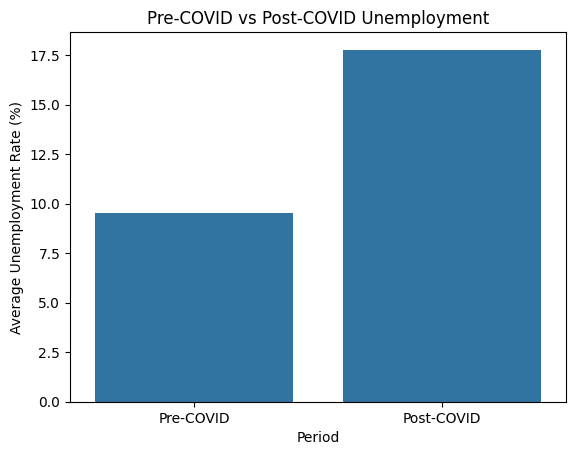

In [19]:
comparison = pd.DataFrame({
    "Period": ["Pre-COVID", "Post-COVID"],
    "Unemployment Rate": [
        pre_covid_avg,
        post_covid_avg
    ]
})

sns.barplot(
    data=comparison,
    x="Period",
    y="Unemployment Rate"
)

plt.title("Pre-COVID vs Post-COVID Unemployment")
plt.ylabel("Average Unemployment Rate (%)")

plt.show()